# Tarea 03 — Web scraping con Selenium y ChromeDriver
## Grupo 1 · Caso de uso: reseñas de **Rappi** en Google Play

| | |
|---|---|
| **Integrantes** | *Ayala Alberca Sebastian<br>Gamarra Chavez, Diego Valentino<br>Reyes Fabian, Jhan Brayan Zamir<br>Jara Espinoza, Angela Lucia* |
| **Curso** | *Taller de Aplicaciones Sociales* |
| **Fuente** | [Rappi en Google Play](https://play.google.com/store/apps/details?id=com.grability.rappi&hl=es_419&gl=PE) |

**Objetivo:** extraer automáticamente ~1000 opiniones en español de una empresa con miles de comentarios,
usando **Selenium** para controlar **Google Chrome** a través de **ChromeDriver**.

**¿Por qué Rappi en Google Play?** Rappi es un marketplace de delivery con más de 2,3 millones de opiniones;
Google Play muestra las reseñas en español sin necesidad de iniciar sesión. Se descartaron Amazon
(exige login para ver más reseñas) y Booking (bloqueos anti-bot).

## 1. Configuración del entorno
Entorno Anaconda `task03` (ver `environment.yml`). La lógica del scraper está en el paquete `src/`;
este notebook la orquesta y muestra los resultados.

`EJECUTAR_SCRAPING = True` abre Chrome y extrae las reseñas de nuevo (~3–4 min).
Con `False` se reutilizan los datos ya extraídos en `data/raw/resenas_crudas.csv`.

In [1]:
EJECUTAR_SCRAPING = True

import platform
import matplotlib.pyplot as plt
import pandas as pd
import selenium
from IPython.display import Image, display

from src import config as cfg
from src.analisis import grafico_calificaciones, grafico_por_dia, resumen
from src.scraper import ejecutar
from src.storage import cargar_crudo, guardar_procesado, limpiar, validar

pd.set_option("display.max_colwidth", 80)
print(f"Python {platform.python_version()} | Selenium {selenium.__version__} | pandas {pd.__version__}")
print(f"URL: {cfg.URL}")
print(f"Meta: {cfg.META} reseñas | Orden: {cfg.ORDEN}")

Python 3.11.17 | Selenium 4.50.0 | pandas 3.0.6
URL: https://play.google.com/store/apps/details?id=com.grability.rappi&hl=es_419&gl=PE
Meta: 1050 reseñas | Orden: Más recientes


## 2. Scraping con Selenium + ChromeDriver
Flujo de `src/scraper.py`:
1. Abre Chrome (Selenium Manager obtiene el ChromeDriver compatible) y carga la página de Rappi.
2. Hace clic en **"Ver todas las opiniones"** y espera el modal (`WebDriverWait`, sin esperas fijas).
3. Ordena por **"Más recientes"** y confirma que el orden cambió.
4. Bucle: lee solo las reseñas nuevas → scroll al fondo del modal → espera el nuevo lote (20 reseñas) →
   pausa aleatoria de 0,8–2 s. Se detiene al llegar a la meta o tras 8 scrolls sin reseñas nuevas.
5. Guarda checkpoints cada 200 reseñas y capturas de pantalla completa como evidencia.

In [2]:
if EJECUTAR_SCRAPING:
    resenas = ejecutar(meta=cfg.META)
else:
    # Evidencia de la última ejecución registrada en scraping.log
    lineas = cfg.ARCHIVO_LOG.read_text(encoding="utf-8").splitlines()
    inicio = max(i for i, l in enumerate(lineas) if "Inicio |" in l)
    print("\n".join(l for l in lineas[inicio:] if "Reseñas:" not in l and l.strip()))

08:28:36 INFO    Chrome 155.0.8059.39 | ChromeDriver 155.0.8059.39


08:28:36 INFO    Inicio | meta=1050 | Chrome 155.0.8059.39 | ChromeDriver 155.0.8059.39


08:28:39 INFO    Captura de pantalla completa: scraping_01_pagina_app.png


08:28:40 INFO    Modal de opiniones abierto


08:28:41 INFO    Captura de pantalla completa: scraping_02_modal_opiniones.png


...

08:31:35 INFO    Checkpoint: 1000 reseñas guardadas


08:31:36 INFO    Captura de pantalla completa: scraping_06_1000_resenas.png


08:31:49 INFO    Captura de pantalla completa: scraping_07_final.png


08:31:49 INFO    Datos en crudo: 1050 reseñas en /home/angela/dev/projects/taps-labs-unmsm/task03/data/raw/resenas_crudas.csv


08:31:49 INFO    Fin | 1050 reseñas | 193 s | motivo: meta alcanzada


### Evidencia: Chrome automatizado en ejecución
Capturas de pantalla completa tomadas automáticamente por el scraper (se observa la barra
*"Un software de prueba automatizado está controlando Chrome"*).

scraping_03_orden_recientes.png


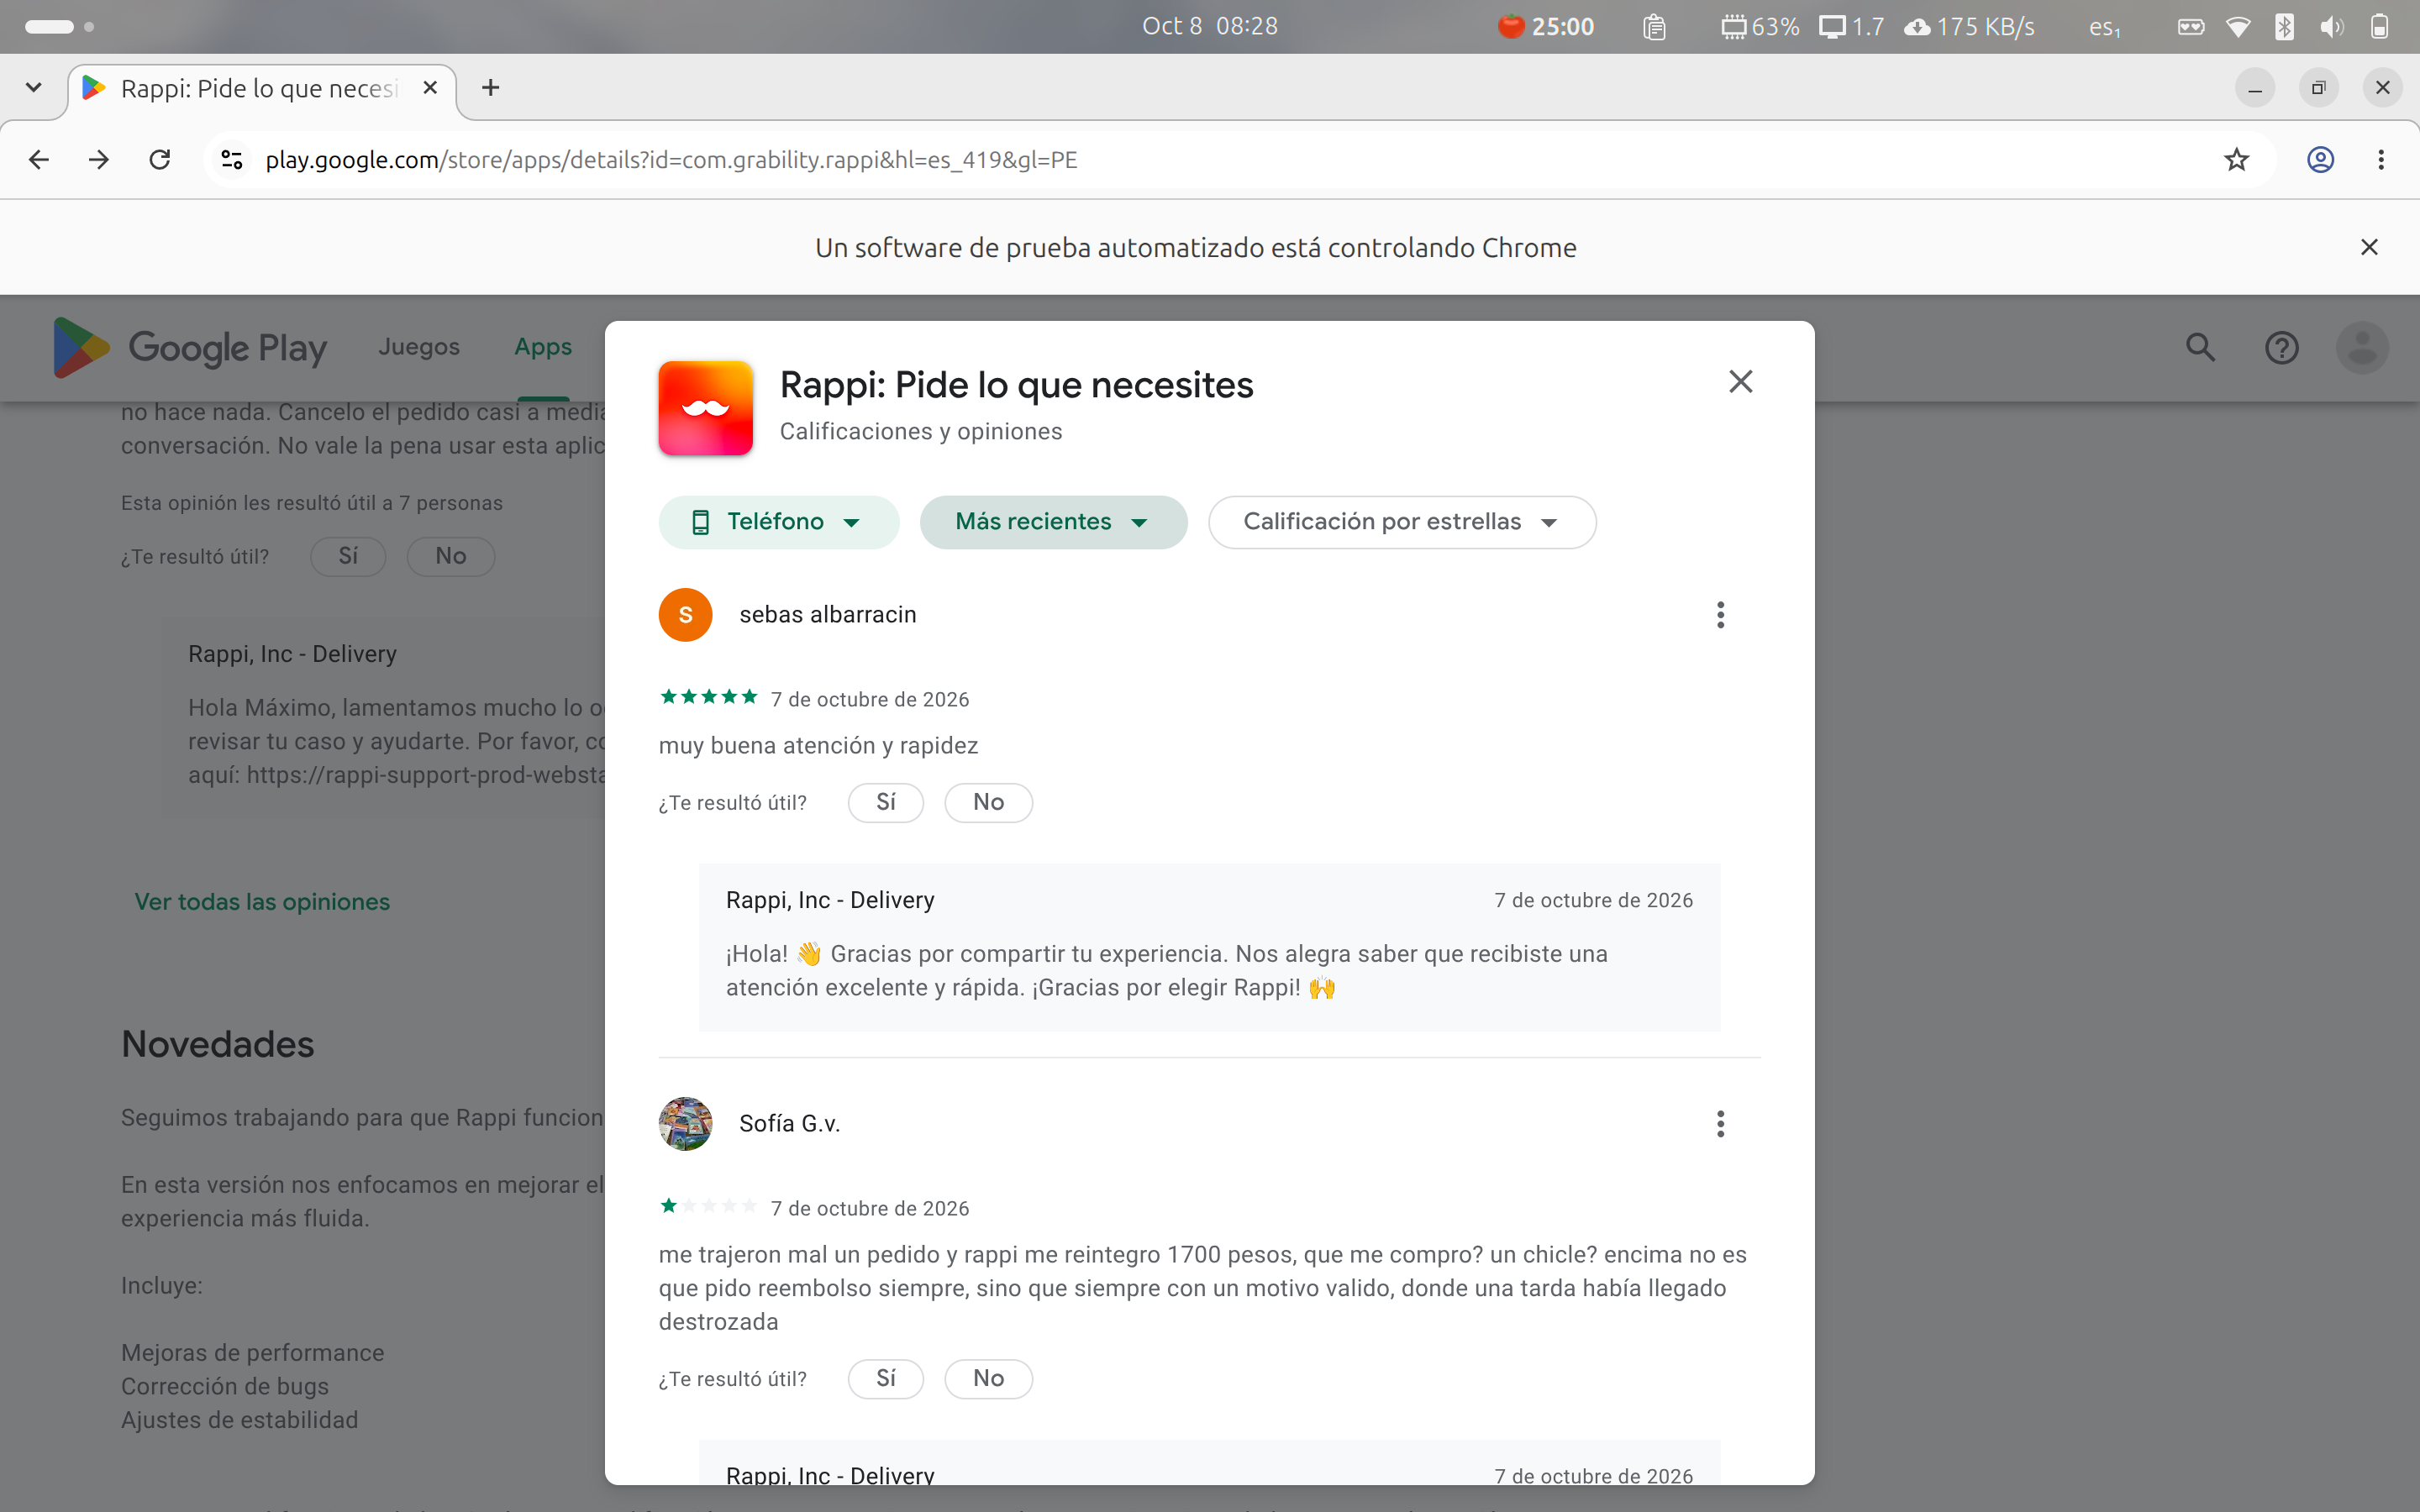

scraping_05_500_resenas.png


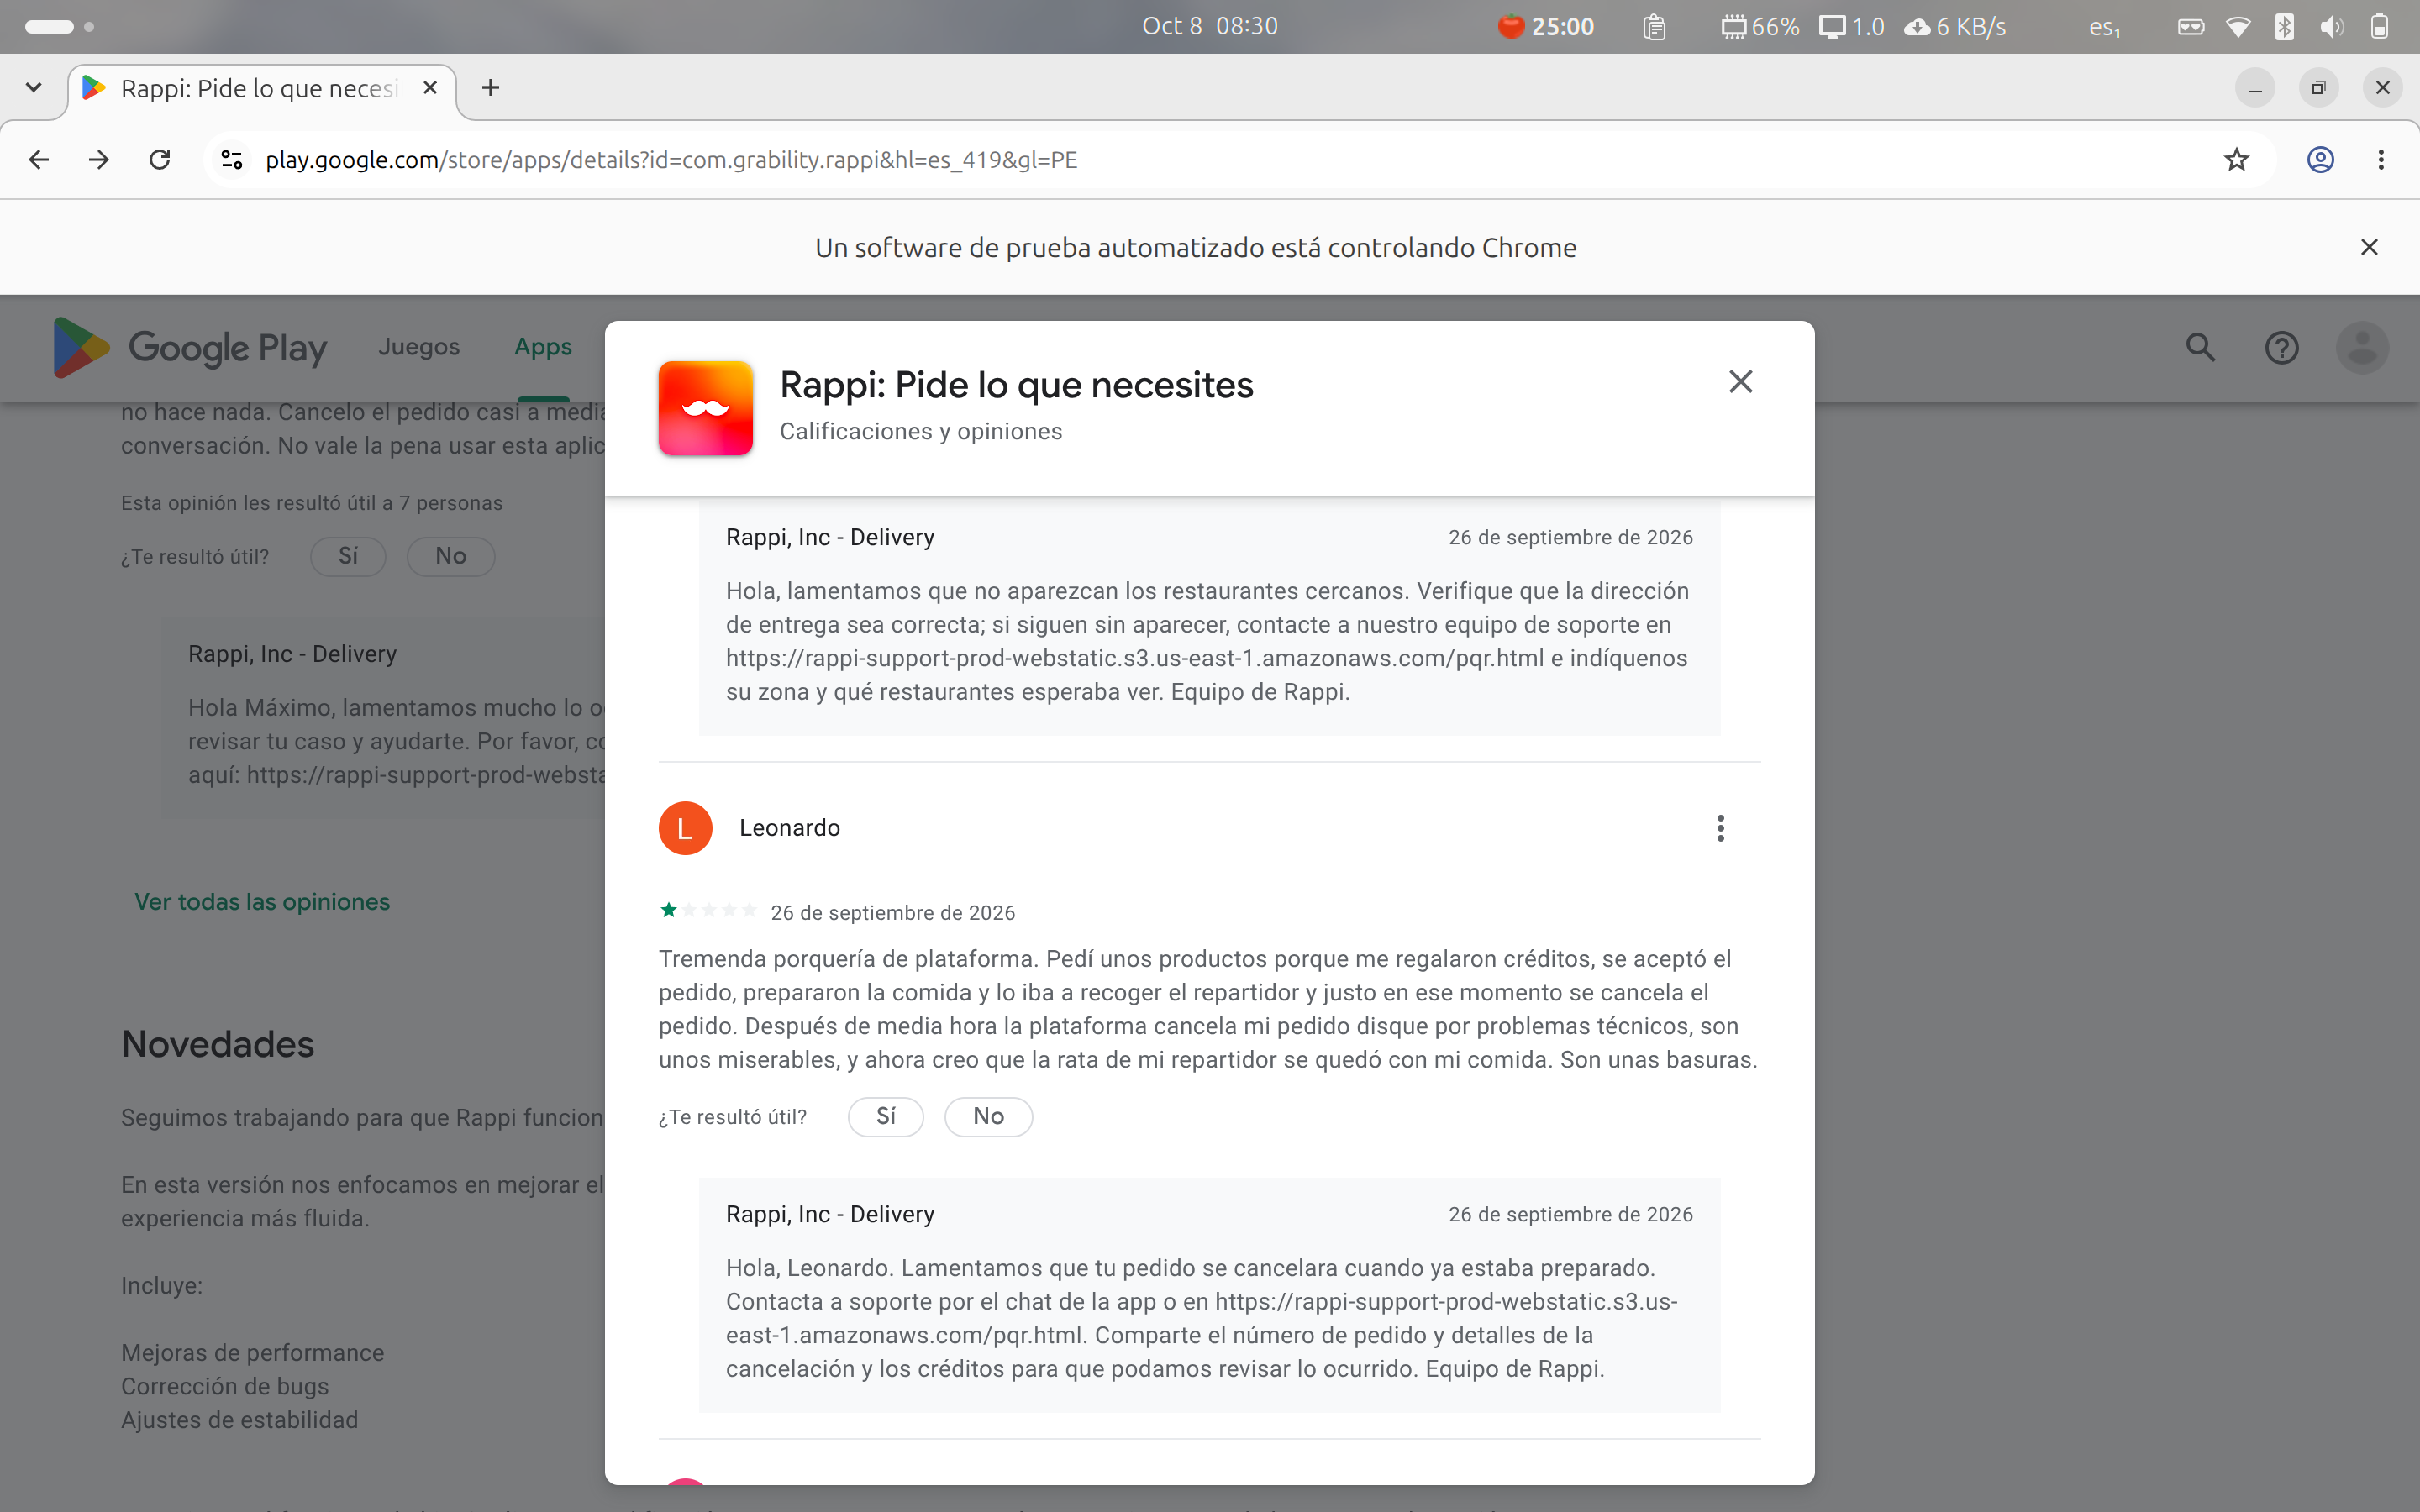

In [3]:
for nombre in ["scraping_03_orden_recientes.png", "scraping_05_500_resenas.png"]:
    print(nombre)
    display(Image(filename=cfg.DIR_CAPTURAS / nombre, width=900))

## 3. Datos en crudo

In [4]:
df_crudo = cargar_crudo()
print(f"{len(df_crudo)} reseñas en crudo, {df_crudo.shape[1]} columnas")
df_crudo.head()

1050 reseñas en crudo, 10 columnas


,id_resena,usuario,calificacion,fecha,comentario,votos_utiles,respuesta_empresa,fecha_respuesta,app,fecha_extraccion
0,d781f04c3f3081a4c2ab17dac237f4d12813f158,sebas albarracin,5,2026-10-07,muy buena atención y rapidez,0,¡Hola! 👋 Gracias por compartir tu experiencia. Nos alegra saber que recibist...,2026-10-07,Rappi,2026-10-08T08:28:44
1,acf1a704528666a7e40fe75a887fb2e326fa788d,Sofía G.v.,1,2026-10-07,"me trajeron mal un pedido y rappi me reintegro 1700 pesos, que me compro? un...",0,"Hola, Sofía. Lamentamos que hayas recibido un pedido en mal estado y que el ...",2026-10-07,Rappi,2026-10-08T08:28:44
2,783ca0d9f0c58804788e49e1974f516de6e8938f,Ezequiel,1,2026-10-07,SE VAN A LA QUIEBRA POR NO TENER SOPORTE PARA CLIENTES Y REPARTIDORES. CHAU ...,0,"Hola Ezequiel, lamentamos que sientas que no hay apoyo para clientes ni repa...",2026-10-07,Rappi,2026-10-08T08:28:44
3,71ff7714aa878723477ec5b5627563b4d1bb9614,Jhonn Alexander,1,2026-10-07,"los pagos con PSE está fallando, una vez ingresado el código en la app. En e...",0,"Hola Jhonn, lamentamos que el pago con PSE quede detenido tras ingresar el c...",2026-10-07,Rappi,2026-10-08T08:28:44
4,0f2f9fa633cf2a67223cdf2e68afee064fadb05e,Ernesto Alonso Alatorre Rubio,3,2026-10-07,le pondria las 5 estrellas si hubiera aparecido mi dirección pero el reparti...,0,"Hola, Ernesto. Lamentamos que tu dirección no apareciera; agradecemos el esf...",2026-10-07,Rappi,2026-10-08T08:28:44


## 4. Limpieza
- **Tipos:** calificación y votos a enteros; fechas a tipo fecha.
- **Duplicados:** por `id_resena` (red de seguridad; el scraper ya filtra en vivo).
- **Texto:** se quitan caracteres invisibles y espacios repetidos; se conservan tildes, ñ, emojis y mayúsculas.
- **Vacíos:** solo se eliminan comentarios totalmente vacíos; los cortos ("ok", "👍") son opiniones válidas.
- **Columnas derivadas:** `longitud_comentario`, `tiene_respuesta`, `dias_respuesta`, `editada_tras_respuesta`.

> **Hallazgo:** en Google Play, si un usuario edita su reseña, la reseña toma la fecha de la edición pero la
> respuesta de Rappi conserva su fecha original. En esos casos la respuesta parece "anterior" a la reseña:
> se marcan con `editada_tras_respuesta = True` y su `dias_respuesta` queda vacío (no es medible).

In [5]:
df, resumen_limpieza = limpiar(df_crudo)
pd.Series(resumen_limpieza, name="cantidad").to_frame()

08:31:49 INFO    Limpieza: {'registros_crudos': 1050, 'duplicados_eliminados': 0, 'vacios_eliminados': 0, 'editadas_tras_respuesta': 60, 'registros_finales': 1050}


,cantidad
registros_crudos,1050
duplicados_eliminados,0
vacios_eliminados,0
editadas_tras_respuesta,60
registros_finales,1050


## 5. Validaciones de calidad
Si alguna falla, la celda se detiene con un error.

In [6]:
for chequeo in validar(df):
    print("✅", chequeo)

08:31:49 INFO    Validaciones superadas: 7/7


✅ cantidad en rango 1000–1100
✅ id_resena único
✅ sin nulos en columnas obligatorias
✅ calificación entre 1 y 5
✅ sin fechas futuras
✅ días de respuesta no negativos
✅ votos no negativos


## 6. Estadísticas descriptivas

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1050 entries, 0 to 1049
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   id_resena               1050 non-null   str           
 1   usuario                 1050 non-null   str           
 2   calificacion            1050 non-null   Int64         
 3   fecha                   1050 non-null   datetime64[us]
 4   comentario              1050 non-null   str           
 5   longitud_comentario     1050 non-null   int64         
 6   votos_utiles            1050 non-null   int64         
 7   tiene_respuesta         1050 non-null   bool          
 8   respuesta_empresa       1047 non-null   str           
 9   fecha_respuesta         1047 non-null   datetime64[us]
 10  dias_respuesta          987 non-null    Int64         
 11  editada_tras_respuesta  1050 non-null   bool          
 12  app                     1050 non-null   str           
 13 

In [8]:
pd.Series(resumen(df), name="valor").to_frame()

,valor
Reseñas,1050
Rango de fechas,13/09/2026 – 07/10/2026
Calificación promedio,1.84
% de 1 estrella,73.4
% respondidas por Rappi,99.7
Días promedio de respuesta,0.0
Longitud media del comentario,161


In [9]:
df[["usuario", "calificacion", "fecha", "comentario", "votos_utiles", "tiene_respuesta"]].sample(5, random_state=1)

,usuario,calificacion,fecha,comentario,votos_utiles,tiene_respuesta
49,Héctor HM,5,2026-10-06,buena app,0,True
779,Casandra,1,2026-09-20,"No permite reprogramar pedidos, hay un error en la nueva actualización, veri...",0,True
358,cutberto becerril,1,2026-09-29,"tres pedidos y ninguno surtido, pésima aplicación, y eso que tengo el de ent...",0,True
991,florencia Rodriguez,1,2026-09-15,NO PIDAN POR RAPPI. Ya es la 3° vez que pido y el Rappi se va a otra direcci...,0,True
639,Julián Andrés,1,2026-09-23,Insuperable lo mala que es la publicidad de Rappi en su canal de WhatsApp. P...,0,True


## 7. Gráficos

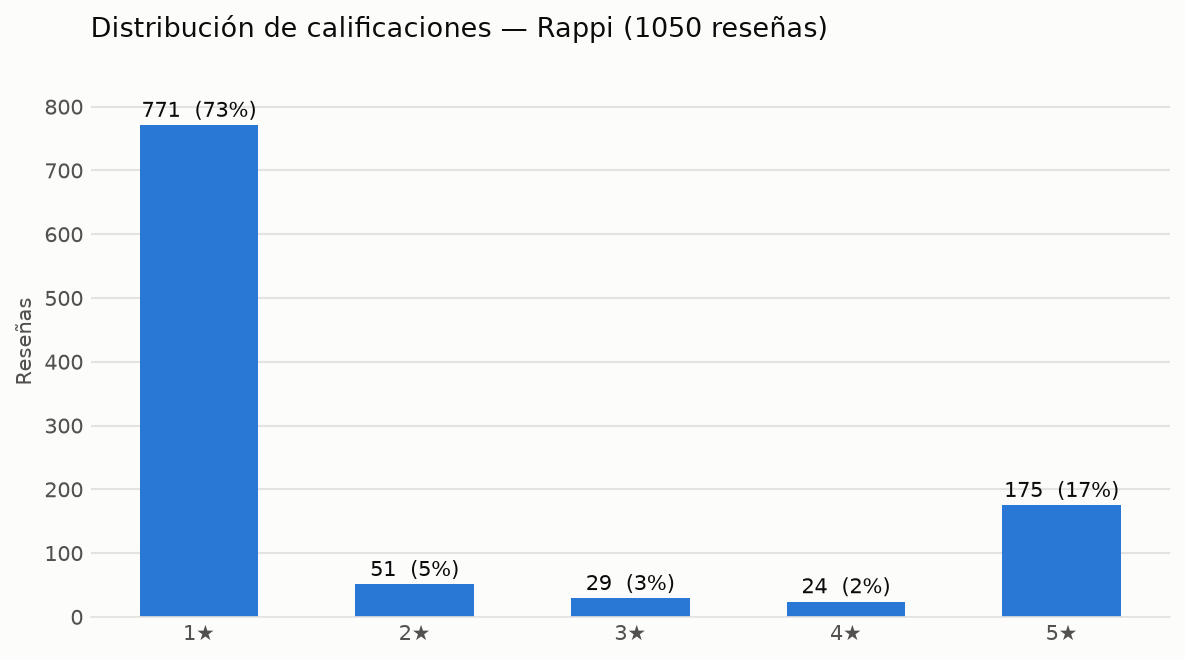

In [10]:
grafico_calificaciones(df)
plt.show()

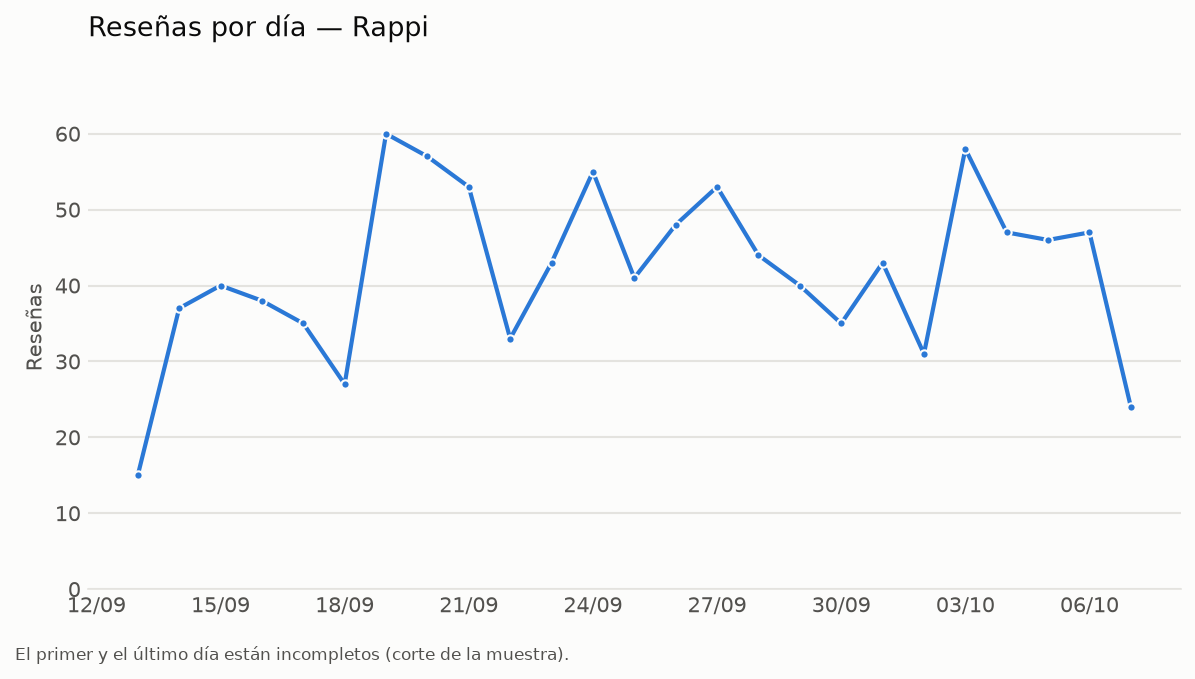

In [11]:
grafico_por_dia(df)
plt.show()

## 8. Exportación y empaquetado (`G1_task03_data.zip`)
Se exportan los datos limpios y se empaquetan en `entregables/G1_task03_data.zip`:
- `G1_task03_resenas_rappi.csv`: UTF-8 con BOM (Excel muestra bien tildes y ñ), fechas AAAA-MM-DD.
- `G1_task03_resenas_rappi.xlsx`: hojas **Reseñas** (encabezado fijo, filtros, fechas reales), **Diccionario** y **Resumen**.
- `LEEME.txt`: fuente, método, cifras clave, diccionario de datos y nota sobre reseñas editadas.

Luego el zip se reabre y se verifica: integridad, contenido, cantidad de filas e ids.

In [12]:
from src.exportacion import diccionario, exportar_y_empaquetar

guardar_procesado(df)
verificacion = exportar_y_empaquetar(df)
print(f"✅ {verificacion['zip']} ({verificacion['tamaño']}) verificado: {verificacion['filas']} reseñas")
for archivo, tamaño in verificacion["archivos"].items():
    print(f"   - {archivo}: {tamaño}")
diccionario(df)

08:31:49 INFO    Datos limpios: 1050 reseñas en /home/angela/dev/projects/taps-labs-unmsm/task03/data/processed/resenas_limpias.csv


08:31:50 INFO    Zip verificado: {'G1_task03_resenas_rappi.csv': '596 KB', 'G1_task03_resenas_rappi.xlsx': '248 KB', 'LEEME.txt': '3 KB'}


✅ G1_task03_data.zip (415 KB) verificado: 1050 reseñas
   - G1_task03_resenas_rappi.csv: 596 KB
   - G1_task03_resenas_rappi.xlsx: 248 KB
   - LEEME.txt: 3 KB


,columna,tipo,descripcion,ejemplo
0,id_resena,texto (40),Identificador único: hash SHA-1 de usuario + fecha + comentario,d781f04c3f3081a4c2ab17dac237f4d12813f158
1,usuario,texto,Nombre público del autor en Google Play,sebas albarracin
2,calificacion,entero 1–5,Estrellas otorgadas por el usuario,5
3,fecha,fecha,Fecha de publicación de la reseña (o de su última edición),2026-10-07
4,comentario,texto,Texto de la reseña (máximo 500 caracteres en Google Play),muy buena atención y rapidez
5,longitud_comentario,entero,Cantidad de caracteres del comentario,28
6,votos_utiles,entero,Personas que marcaron la reseña como útil (0 si ninguna),0
7,tiene_respuesta,booleano,True si Rappi respondió la reseña,True
8,respuesta_empresa,texto / vacío,Texto de la respuesta de Rappi; vacío si no respondió,¡Hola! 👋 Gracias por compartir tu experiencia. Nos alegra sa
9,fecha_respuesta,fecha / vacío,Fecha de la respuesta de Rappi,2026-10-07


## 9. Presentación de evidencia (`G1_task03_evidencia.pdf`)
Se arma la presentación (15 diapositivas) con las capturas, el registro y las cifras de **esta misma ejecución**,
y se exporta a PDF con LibreOffice en `entregables/`. La copia editable queda en `evidencia/G1_task03_evidencia.pptx`.

08:31:50 INFO    Limpieza: {'registros_crudos': 1050, 'duplicados_eliminados': 0, 'vacios_eliminados': 0, 'editadas_tras_respuesta': 60, 'registros_finales': 1050}


08:31:52 INFO    Presentación generada: /home/angela/dev/projects/taps-labs-unmsm/task03/entregables/G1_task03_evidencia.pdf (15 diapositivas; editable en evidencia/G1_task03_evidencia.pptx)


✅ G1_task03_evidencia.pdf (1.7 MB) en entregables/


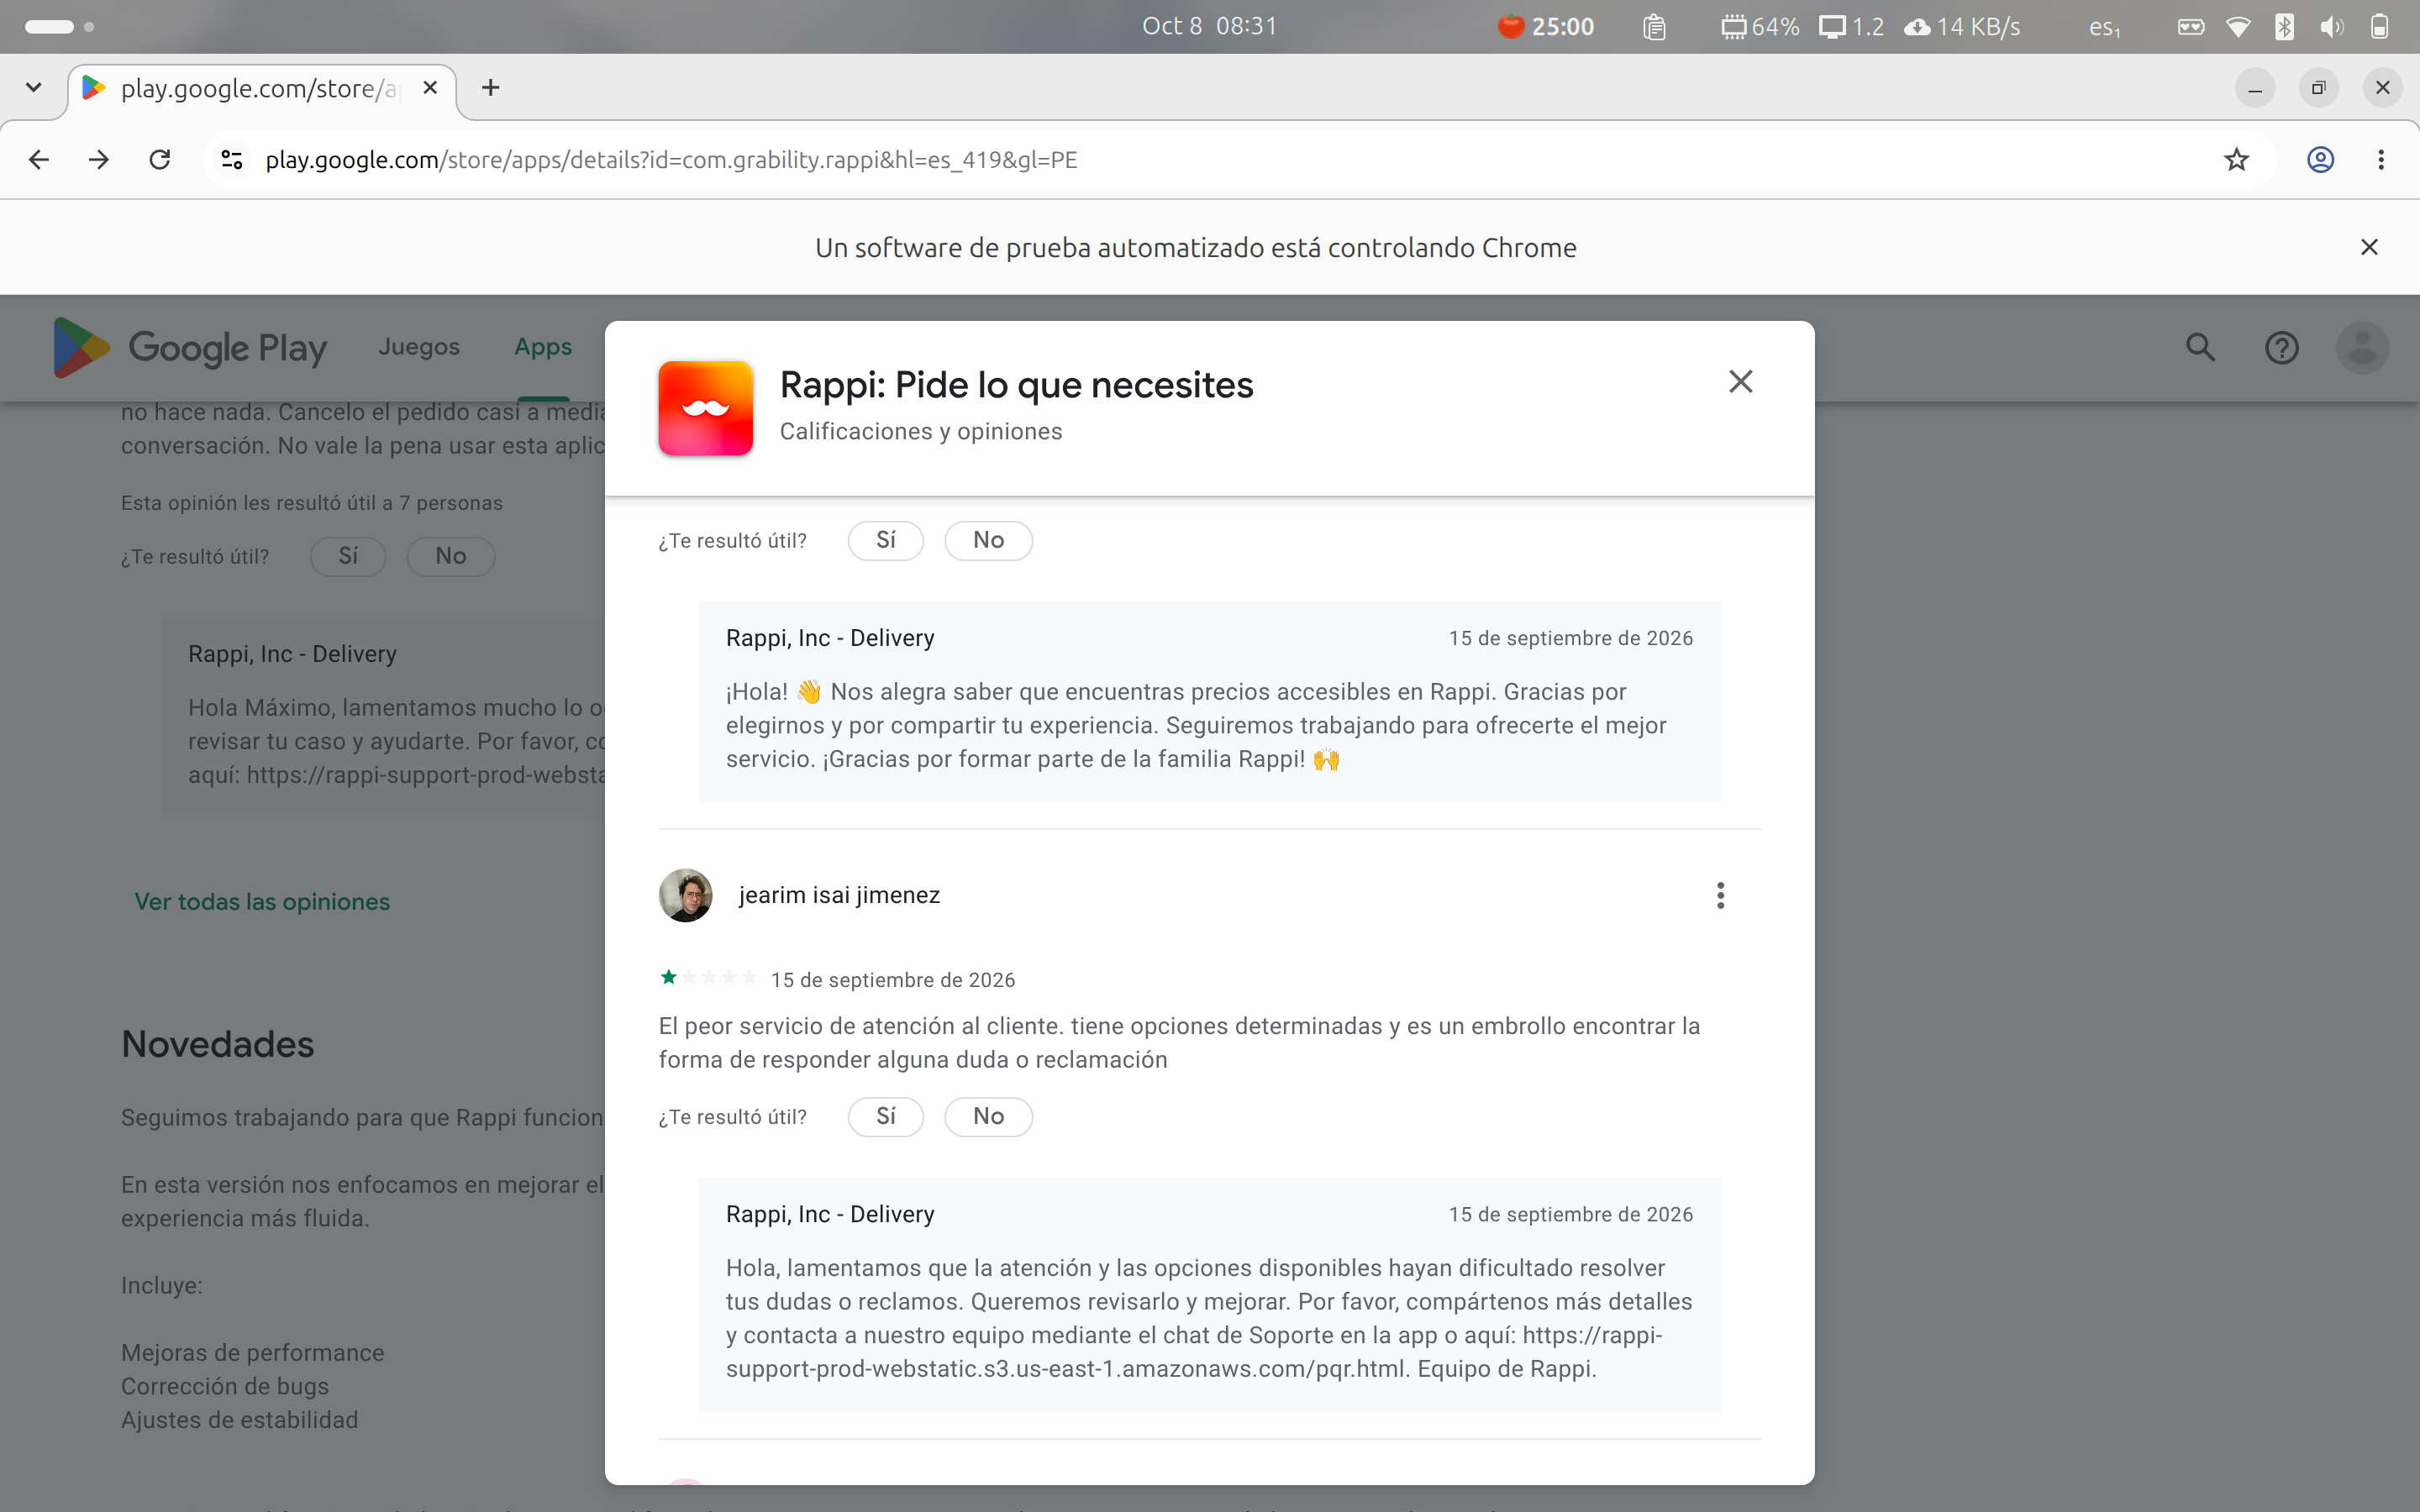

In [13]:
from src.presentacion import generar_ppt

pdf = generar_ppt()
print(f"✅ {pdf.name} ({pdf.stat().st_size / 1024 ** 2:.1f} MB) en {pdf.parent.relative_to(cfg.BASE)}/")
display(Image(filename=cfg.DIR_CAPTURAS / "scraping_06_1000_resenas.png", width=600))

## 10. Conclusiones
- Se extrajeron **1050 reseñas** en español con Selenium y ChromeDriver, dentro del rango de ~1000 registros
  requerido, sin duplicados y con todas las validaciones superadas.
- Las reseñas recientes son mayoritariamente negativas (**~73 % de 1 estrella**), aunque la app tiene 4,6★ global:
  los usuarios insatisfechos son quienes más escriben, y los temas frecuentes son soporte, cobros y demoras.
- Rappi responde a casi todas las reseñas (**~99,7 %**), normalmente el mismo día.
- Dificultades resueltas: clases HTML ofuscadas (selectores centralizados en `config.py`), carga dinámica por
  scroll (espera por lote con `WebDriverWait`), un clic de ordenamiento que se perdía por la animación del menú
  (confirmación y reintentos) y fechas de reseñas editadas.
- Uso responsable: fines académicos, sin inicio de sesión, una sola sesión y pausas aleatorias entre scrolls;
  `robots.txt` no restringe las páginas de detalle de apps.